

# Two Problems for Lab 3:


# Problem 1: Gender Recognition by Voice

From the description file at https://data.world/ml-research/gender-recognition-by-voice:

In order to analyze gender by voice and speech, a training database was required. A database was built using thousands of samples of male and female voices, each labeled by their gender of male or female. Voice samples were collected from the following resources:

*  [The Harvard-Haskins Database of Regularly-Timed Speech](http://nsi.wegall.net/)
*  Telecommunications & Signal Processing Laboratory (TSP) Speech Database at McGill University
*  [VoxForge Speech Corpus](http://www.repository.voxforge1.org/downloads/SpeechCorpus/Trunk/Audio/Main/8kHz_16bit/)
*  [Festvox CMU_ARCTIC Speech Database at Carnegie Mellon University](http://festvox.org/cmu_arctic/dbs_awb.html)

Each voice sample is stored as a .WAV file, which is then pre-processed for acoustic analysis using the specan function from the WarbleR R package. Specan measures 22 acoustic parameters on acoustic signals for which the start and end times are provided.

The output from the pre-processed WAV files were saved into a CSV file, containing 3168 rows and 21 columns (20 columns for each feature and one label column for the classification of male or female). You can download the pre-processed dataset in CSV format, using the link above
Acoustic Properties Measured

The following acoustic properties of each voice are measured:

*    __duration:__ length of signal
*    __meanfreq:__ mean frequency (in kHz)
*    __sd:__ standard deviation of frequency
*    __median:__ median frequency (in kHz)
*    __Q25:__ first quantile (in kHz)
*    __Q75:__ third quantile (in kHz)
*    __IQR:__ interquantile range (in kHz)
*    __skew:__ skewness (see note in specprop description)
*    __kurt:__ kurtosis (see note in specprop description)
*    __sp.ent:__ spectral entropy
*    __sfm:__ spectral flatness
*    __mode:__ mode frequency
*    __centroid:__ frequency centroid (see specprop)
*    __peakf:__ peak frequency (frequency with highest energy)
*    __meanfun:__ average of fundamental frequency measured across acoustic signal
*    __minfun:__ minimum fundamental frequency measured across acoustic signal
*    __maxfun:__ maximum fundamental frequency measured across acoustic signal
*    __meandom:__ average of dominant frequency measured across acoustic signal
*    __mindom:__ minimum of dominant frequency measured across acoustic signal
*    __maxdom:__ maximum of dominant frequency measured across acoustic signal
*    __dfrange:__ range of dominant frequency measured across acoustic signal
*    __modindx:__ modulation index. Calculated as the accumulated absolute difference between adjacent measurements of fundamental frequencies divided by the frequency range

The gender of the speaker is given in the __label__ column. 

Note, the features for duration and peak frequency (peakf) were removed from training. Duration refers to the length of the recording, which for training, is cut off at 20 seconds. Peakf was omitted from calculation due to time and CPU constraints in calculating the value. In this case, all records will have the same value for duration (20) and peak frequency (0).

Load file using the code below. 

#### Question 1:

1. Exploratory analysis for Categorical Targets as in the master file. 
2. Which two features are most indicative of gendered voice?

#### Question 2:

Preform Linear Regression, Logistic Regression, and Quadratic Discriminant Analysis on the features, graphing the resulting fits. How does the two feature fit compare to the fit on all features?

In [4]:
import pandas as pd

data = pd.read_csv("data/voice.csv")

data

,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3163,0.131884,0.084734,0.153707,0.049285,0.201144,0.151859,1.762129,6.630383,0.962934,0.763182,...,0.131884,0.182790,0.083770,0.262295,0.832899,0.007812,4.210938,4.203125,0.161929,female
3164,0.116221,0.089221,0.076758,0.042718,0.204911,0.162193,0.693730,2.503954,0.960716,0.709570,...,0.116221,0.188980,0.034409,0.275862,0.909856,0.039062,3.679688,3.640625,0.277897,female
3165,0.142056,0.095798,0.183731,0.033424,0.224360,0.190936,1.876502,6.604509,0.946854,0.654196,...,0.142056,0.209918,0.039506,0.275862,0.494271,0.007812,2.937500,2.929688,0.194759,female
3166,0.143659,0.090628,0.184976,0.043508,0.219943,0.176435,1.591065,5.388298,0.950436,0.675470,...,0.143659,0.172375,0.034483,0.250000,0.791360,0.007812,3.593750,3.585938,0.311002,female


## Question 1
### Part 1: Exploratory Analysis

In [5]:
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns

plt.rcParams["figure.dpi"] = 72  ## keep inline images small so PyCharm doesn't hang

In [6]:
data.describe()

,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,mode,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx
count,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000
mean,0.180907,0.057126,0.185621,0.140456,0.224765,0.084309,3.140168,36.568461,0.895127,0.408216,0.165282,0.180907,0.142807,0.036802,0.258842,0.829211,0.052647,5.047277,4.994630,0.173752
std,0.029918,0.016652,0.036360,0.048680,0.023639,0.042783,4.240529,134.928661,0.044980,0.177521,0.077203,0.029918,0.032304,0.019220,0.030077,0.525205,0.063299,3.521157,3.520039,0.119454
min,0.039363,0.018363,0.010975,0.000229,0.042946,0.014558,0.141735,2.068455,0.738651,0.036876,0.000000,0.039363,0.055565,0.009775,0.103093,0.007812,0.004883,0.007812,0.000000,0.000000
25%,0.163662,0.041954,0.169593,0.111087,0.208747,0.042560,1.649569,5.669547,0.861811,0.258041,0.118016,0.163662,0.116998,0.018223,0.253968,0.419828,0.007812,2.070312,2.044922,0.099766
50%,0.184838,0.059155,0.190032,0.140286,0.225684,0.094280,2.197101,8.318463,0.901767,0.396335,0.186599,0.184838,0.140519,0.046110,0.271186,0.765795,0.023438,4.992188,4.945312,0.139357
75%,0.199146,0.067020,0.210618,0.175939,0.243660,0.114175,2.931694,13.648905,0.928713,0.533676,0.221104,0.199146,0.169581,0.047904,0.277457,1.177166,0.070312,7.007812,6.992188,0.209183
max,0.251124,0.115273,0.261224,0.247347,0.273469,0.252225,34.725453,1309.612887,0.981997,0.842936,0.280000,0.251124,0.237636,0.204082,0.279114,2.957682,0.458984,21.867188,21.843750,0.932374


In [7]:
## Features X and target y
X = data.drop(columns=["label"])
y = data["label"]

## Normalize: center on mean, divide by std
X = (X - X.mean()) / X.std()
X.describe()

,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,mode,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx
count,3.168000e+03,3.168000e+03,3.168000e+03,3.168000e+03,3.168000e+03,3.168000e+03,3.168000e+03,3168.000000,3.168000e+03,3.168000e+03,3.168000e+03,3.168000e+03,3.168000e+03,3.168000e+03,3.168000e+03,3.168000e+03,3.168000e+03,3.168000e+03,3.168000e+03,3.168000e+03
mean,2.512020e-16,7.177199e-17,-8.971499e-17,-1.076580e-16,-1.085551e-15,1.435440e-16,-8.522924e-17,0.000000,2.512020e-15,-2.870880e-16,1.435440e-16,2.512020e-16,-5.024040e-16,1.704585e-16,-1.220124e-15,-2.332590e-16,-7.177199e-17,7.177199e-17,-1.794300e-17,-4.934325e-17
std,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
min,-4.731066e+00,-2.327777e+00,-4.803229e+00,-2.880601e+00,-7.691381e+00,-1.630357e+00,-7.070892e-01,-0.255691,-3.478836e+00,-2.091807e+00,-2.140872e+00,-4.731066e+00,-2.700601e+00,-1.406176e+00,-5.178304e+00,-1.563958e+00,-7.545755e-01,-1.431196e+00,-1.418913e+00,-1.454543e+00
25%,-5.763944e-01,-9.111334e-01,-4.408165e-01,-6.033124e-01,-6.776157e-01,-9.758452e-01,-3.515125e-01,-0.229002,-7.406945e-01,-8.459608e-01,-6.122303e-01,-5.763944e-01,-7.989074e-01,-9.666296e-01,-1.620488e-01,-7.794727e-01,-7.082925e-01,-8.454507e-01,-8.379759e-01,-6.193636e-01
50%,1.314199e-01,1.218547e-01,1.213335e-01,-3.475208e-03,3.888670e-02,2.330498e-01,-2.223937e-01,-0.209370,1.476175e-01,-6.692869e-02,2.761141e-01,1.314199e-01,-7.083289e-02,4.842729e-01,4.104155e-01,-1.207455e-01,-4.614500e-01,-1.564521e-02,-1.401041e-02,-2.879298e-01
75%,6.096510e-01,5.941816e-01,6.874959e-01,7.289110e-01,7.993273e-01,6.980735e-01,-4.916214e-02,-0.169864,7.467041e-01,7.067315e-01,7.230590e-01,6.096510e-01,8.287991e-01,5.776489e-01,6.188852e-01,6.625126e-01,2.790774e-01,5.567874e-01,5.674817e-01,2.966132e-01
max,2.346999e+00,3.491858e+00,2.079304e+00,2.195809e+00,2.060318e+00,3.924821e+00,7.448431e+00,9.434944,1.931313e+00,2.448833e+00,1.485929e+00,2.346999e+00,2.935500e+00,8.703446e+00,6.739858e-01,4.052648e+00,6.419284e+00,4.776814e+00,4.786629e+00,6.350730e+00


label
male      1584
female    1584
Name: count, dtype: int64

Roughly 0.5 male to 0.5 female


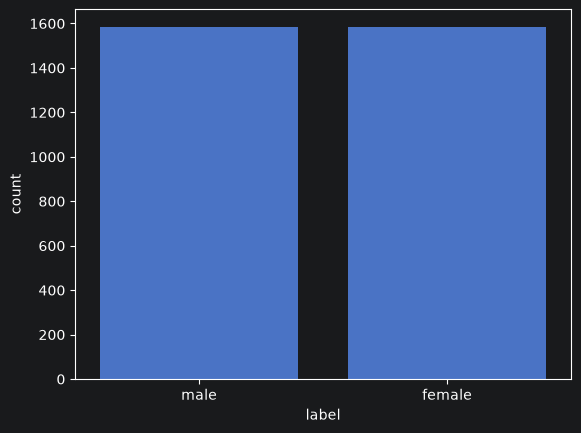

In [8]:
display(y.value_counts())
sns.countplot(x="label", data=data)

F, M = y.value_counts()[["female", "male"]]
print("Roughly", M/(M+F), "male to", F/(M+F), "female")

Text(0.5, 1.0, 'Feature Correlation')

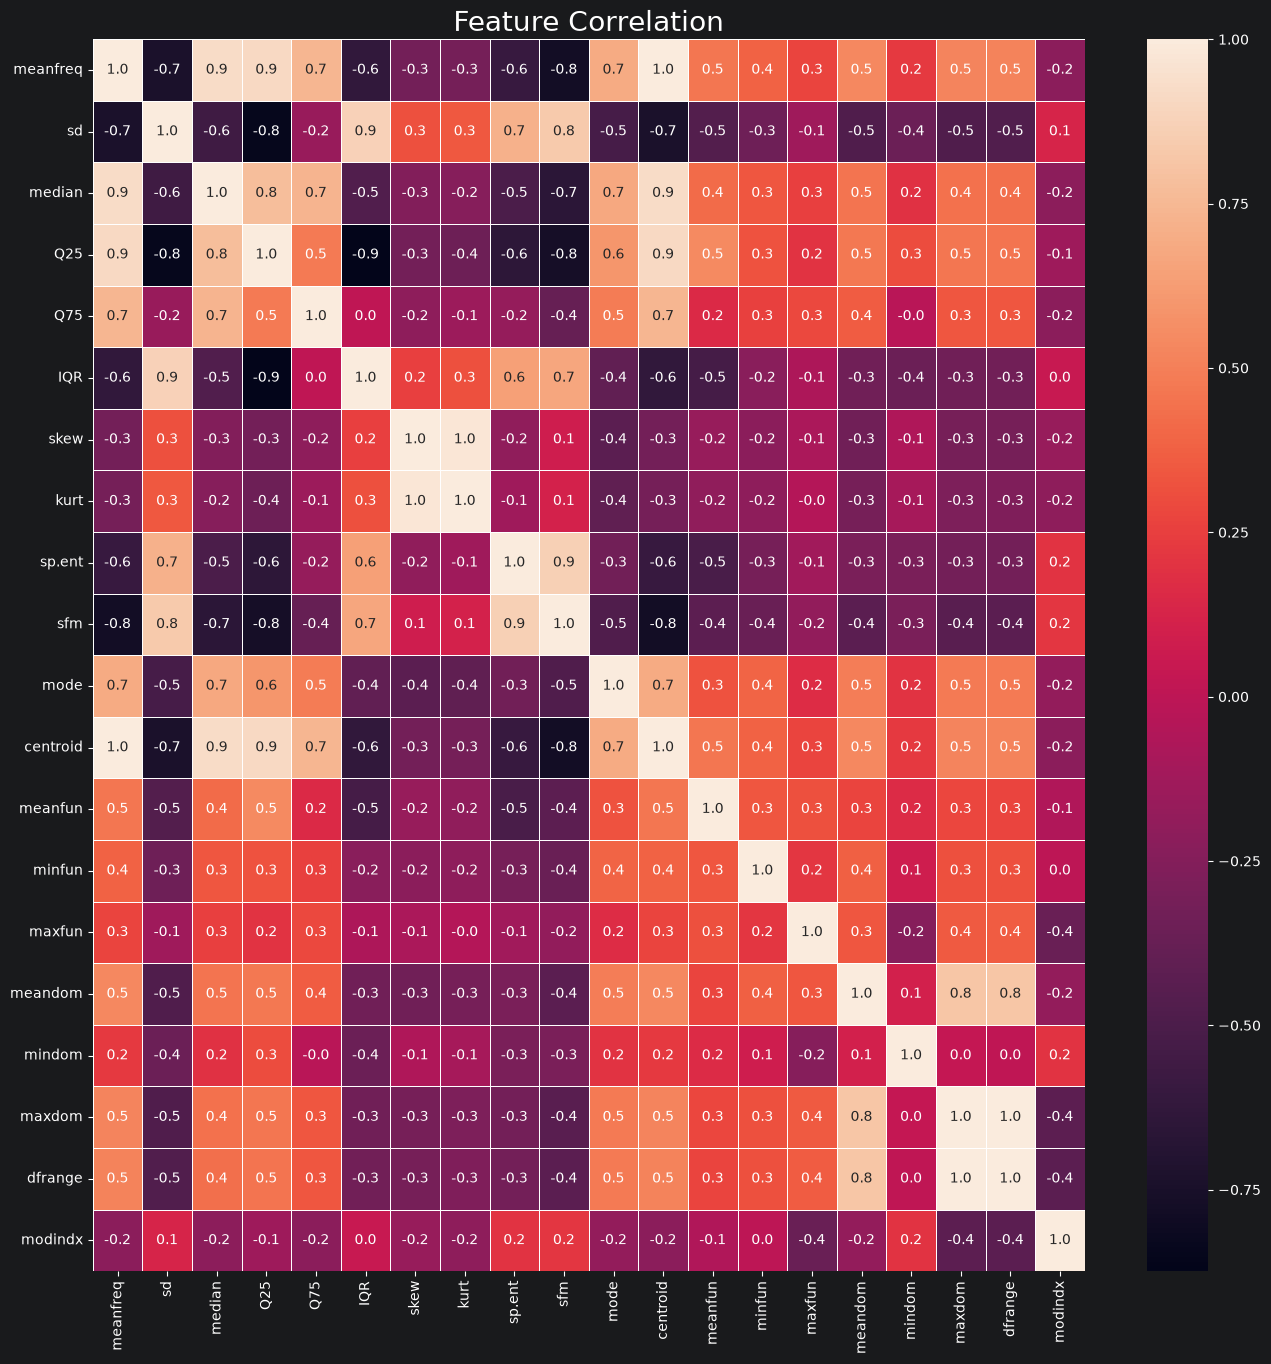

In [9]:
## Correlation among all features
f, ax = plt.subplots(figsize=(10, 10))
sns.heatmap(X.corr(), annot=True, linewidth=.5, fmt='.1f', annot_kws={"size": 7})
ax.set_title("Feature Correlation", fontsize=20)

Text(0.5, 1.0, 'Correlation for Female')

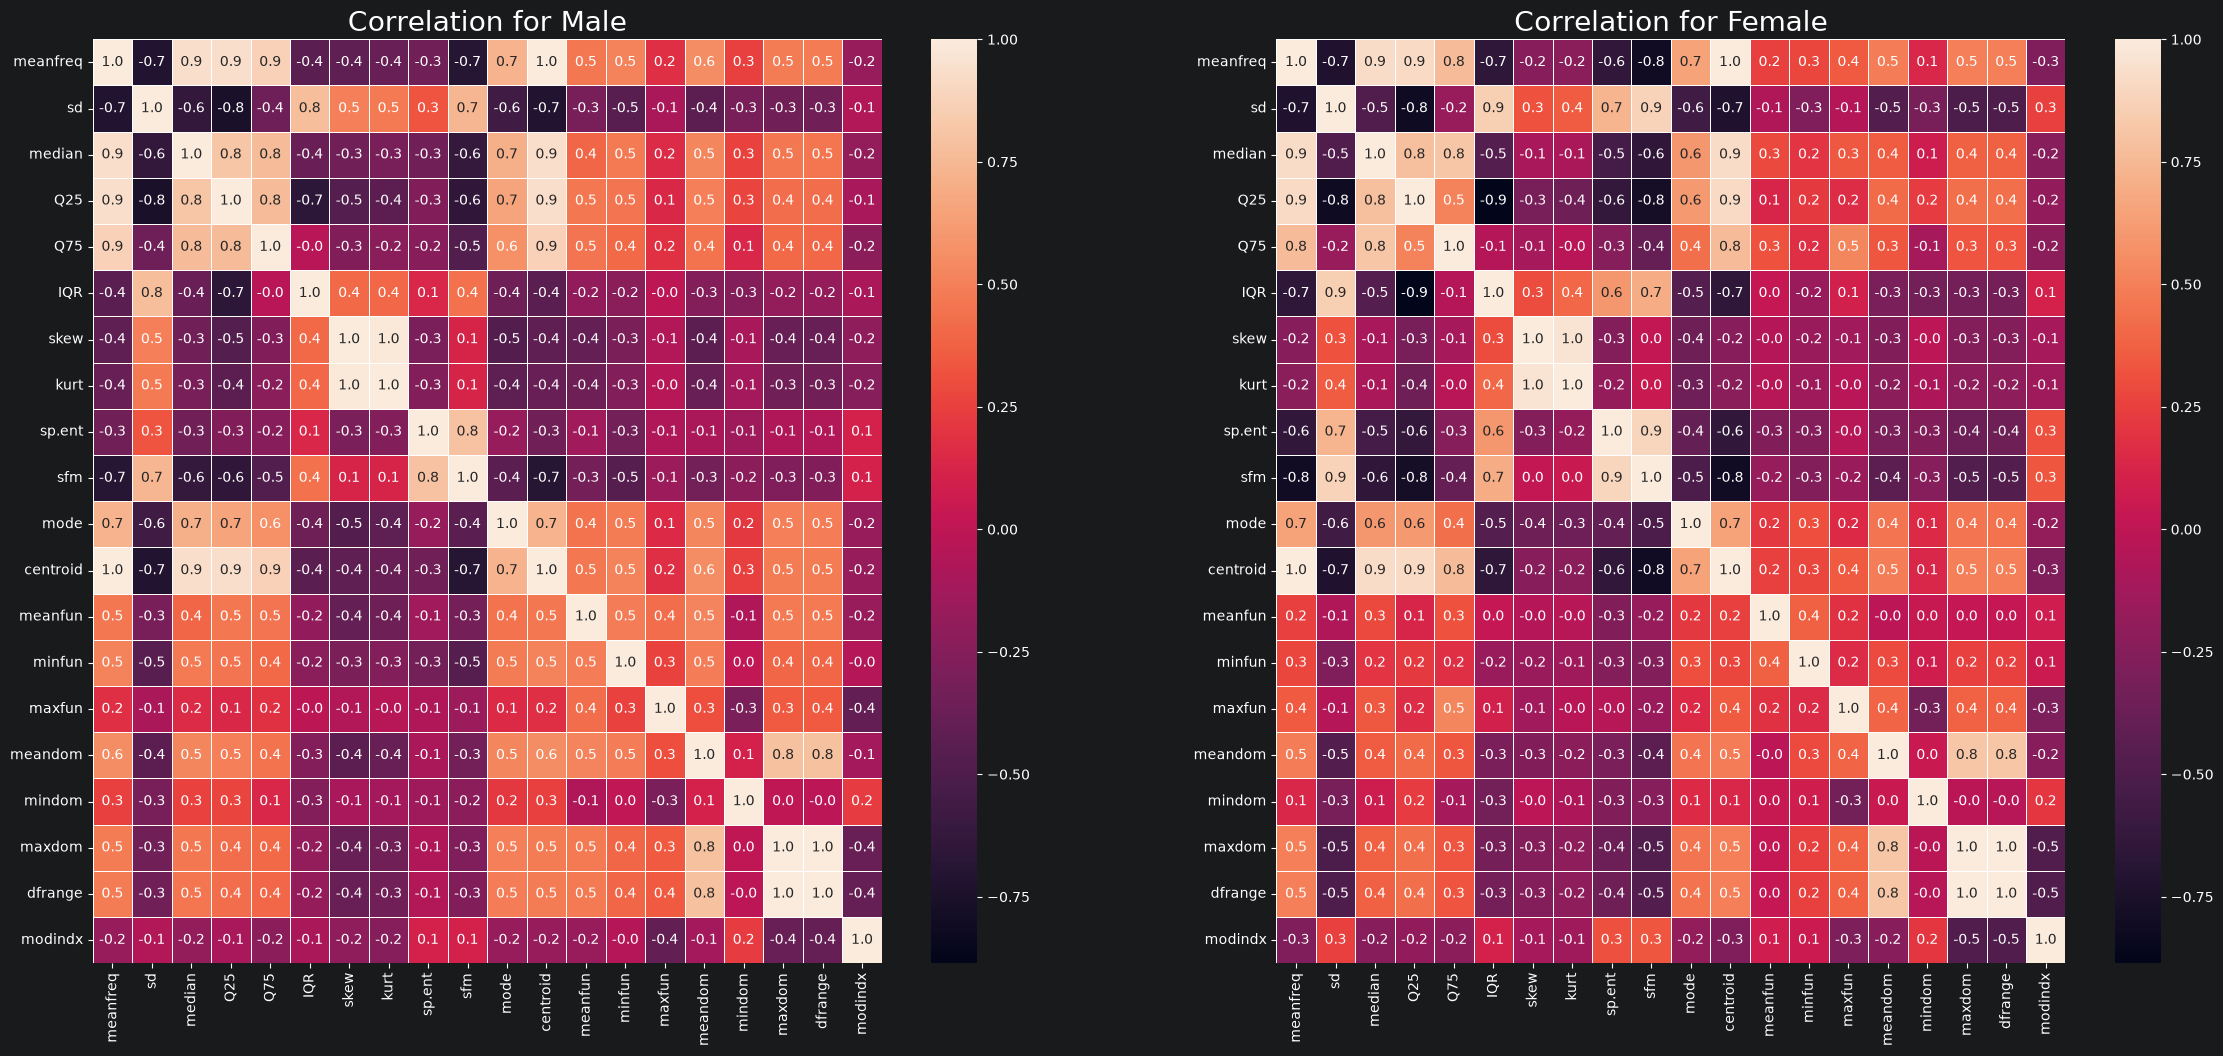

In [11]:
## Correlation within each class, on a shared color scale
I_m = y == "male"
I_f = y == "female"

vmin = min(X[I_m].corr().min().min(), X[I_f].corr().min().min())
vmax = max(X[I_m].corr().max().max(), X[I_f].corr().max().max())

f, axes = plt.subplots(1, 2, figsize=(20, 8))
sns.heatmap(X[I_m].corr(), annot=True, linewidth=.5, fmt='.1f', annot_kws={"size": 7}, ax=axes[0], vmin=vmin, vmax=vmax)
sns.heatmap(X[I_f].corr(), annot=True, linewidth=.5, fmt='.1f', annot_kws={"size": 7}, ax=axes[1], vmin=vmin, vmax=vmax)
axes[0].set_title("Correlation for Male", fontsize=20)
axes[1].set_title("Correlation for Female", fontsize=20)

Text(0.5, 1.0, 'Correlation Difference Between Male and Female')

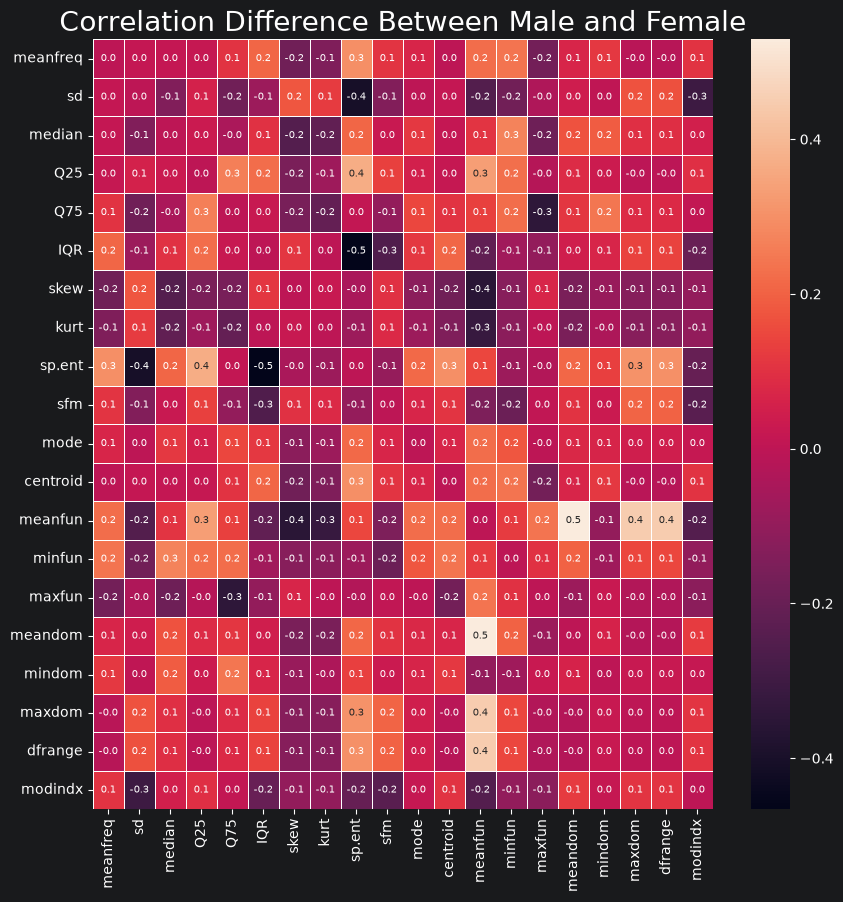

In [15]:
f, ax = plt.subplots(figsize=(10, 10))
sns.heatmap(X[I_m].corr() - X[I_f].corr(), annot=True, linewidth=.5, fmt='.1f', annot_kws={"size": 7})
ax.set_title("Correlation Difference Between Male and Female", fontsize=20)

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19],
 [Text(0, 0, 'meanfreq'),
  Text(1, 0, 'sd'),
  Text(2, 0, 'median'),
  Text(3, 0, 'Q25'),
  Text(4, 0, 'Q75'),
  Text(5, 0, 'IQR'),
  Text(6, 0, 'skew'),
  Text(7, 0, 'kurt'),
  Text(8, 0, 'sp.ent'),
  Text(9, 0, 'sfm'),
  Text(10, 0, 'mode'),
  Text(11, 0, 'centroid'),
  Text(12, 0, 'meanfun'),
  Text(13, 0, 'minfun'),
  Text(14, 0, 'maxfun'),
  Text(15, 0, 'meandom'),
  Text(16, 0, 'mindom'),
  Text(17, 0, 'maxdom'),
  Text(18, 0, 'dfrange'),
  Text(19, 0, 'modindx')])

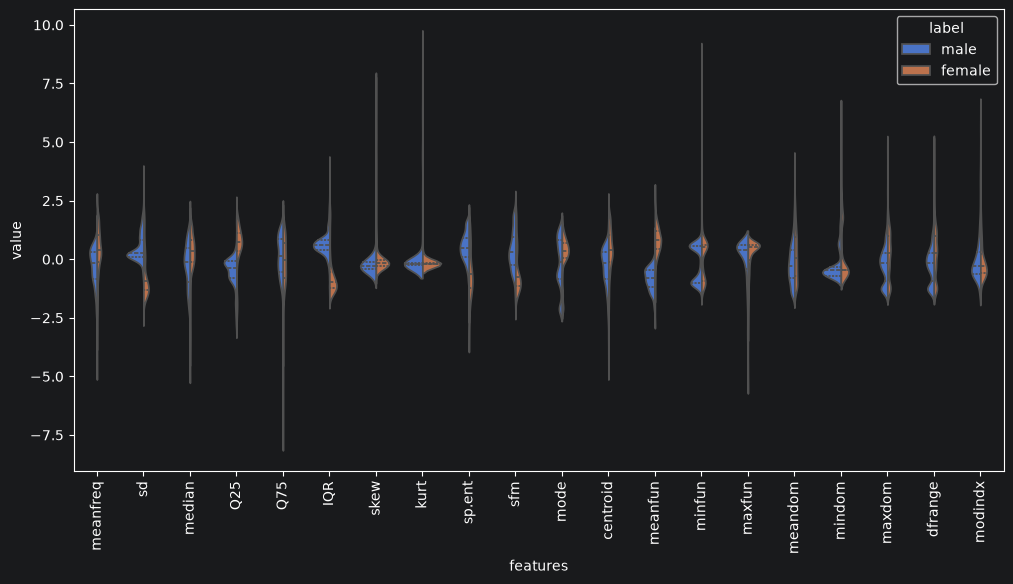

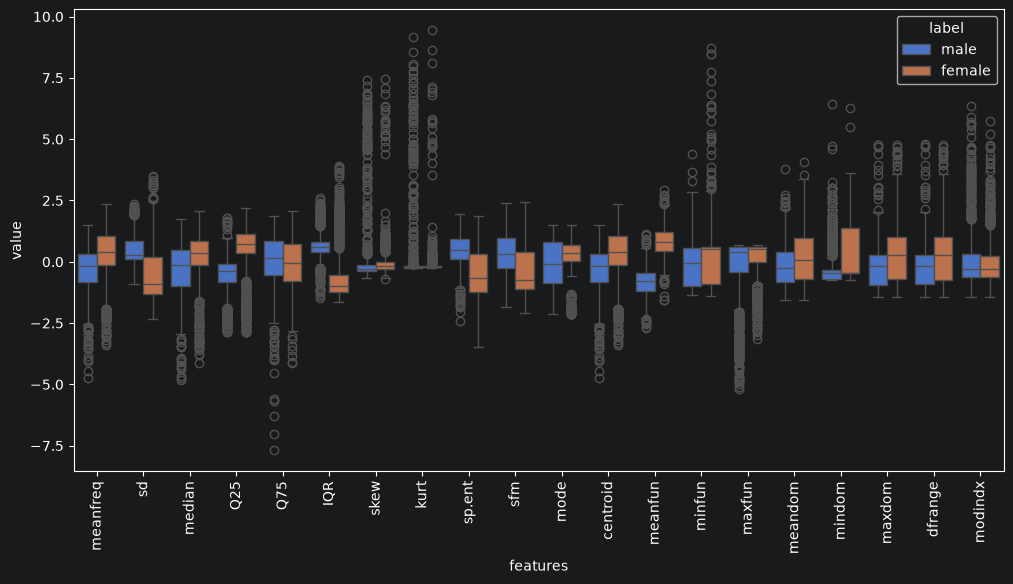

In [16]:
## Violin and box plots of every normalized feature, split by label
vio = pd.concat([y, X], axis=1)
vio = pd.melt(vio, id_vars="label", var_name="features", value_name="value")

plt.figure(figsize=(12, 6))
sns.violinplot(x="features", y="value", hue="label", data=vio, split=True, inner="quart")
plt.xticks(rotation=90)

plt.figure(figsize=(12, 6))
sns.boxplot(x="features", y="value", hue="label", data=vio)
plt.xticks(rotation=90)

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19],
 [Text(0, 0, 'meanfreq'),
  Text(1, 0, 'sd'),
  Text(2, 0, 'median'),
  Text(3, 0, 'Q25'),
  Text(4, 0, 'Q75'),
  Text(5, 0, 'IQR'),
  Text(6, 0, 'skew'),
  Text(7, 0, 'kurt'),
  Text(8, 0, 'sp.ent'),
  Text(9, 0, 'sfm'),
  Text(10, 0, 'mode'),
  Text(11, 0, 'centroid'),
  Text(12, 0, 'meanfun'),
  Text(13, 0, 'minfun'),
  Text(14, 0, 'maxfun'),
  Text(15, 0, 'meandom'),
  Text(16, 0, 'mindom'),
  Text(17, 0, 'maxdom'),
  Text(18, 0, 'dfrange'),
  Text(19, 0, 'modindx')])

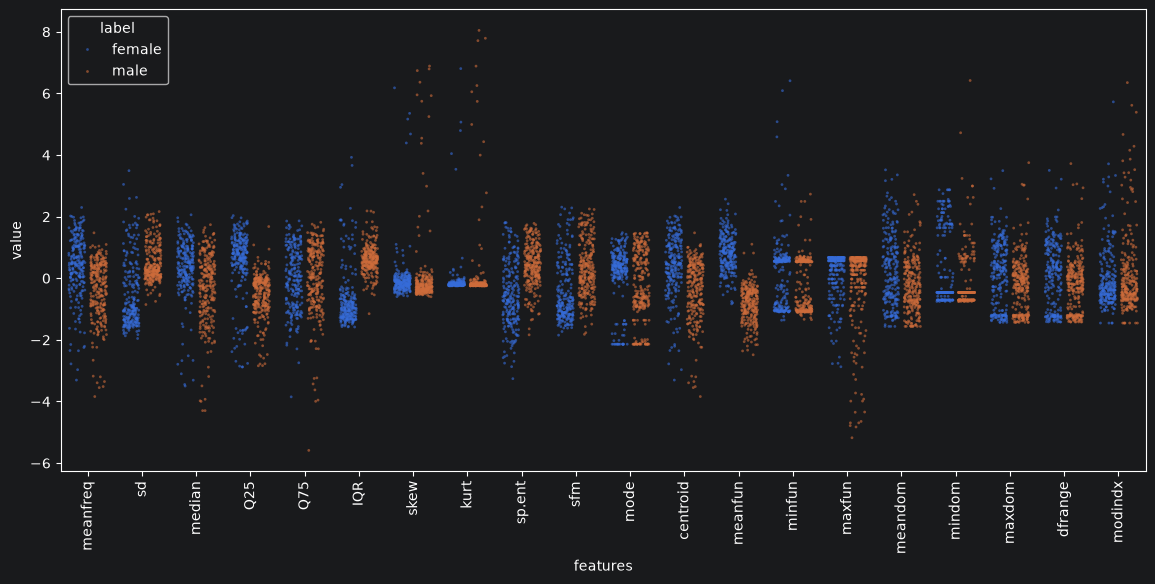

In [19]:
## Strip plot on a random subsample. A swarm plot can't place the many tied values in
## features like maxfun/mindom/modindx, so we jitter the points instead.
vio_s = pd.concat([y, X], axis=1).sample(500, random_state=0)
vio_s = pd.melt(vio_s, id_vars="label", var_name="features", value_name="value")

plt.figure(figsize=(14, 6))
sns.stripplot(x="features", y="value", hue="label", data=vio_s, size=2, jitter=0.3, dodge=True, alpha=.6)
plt.xticks(rotation=90)

### Part 2: Which two features are most indicative of gendered voice?

In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

y_num = (y == "male").astype(int)

rank = pd.DataFrame({
    ## standardized gap between the class means (X is already normalized)
    "mean_diff": (X[I_m].mean() - X[I_f].mean()).abs(),
    ## correlation of each feature with the 0/1 label
    "corr_w_label": X.corrwith(y_num).abs(),
    ## 5-fold CV accuracy of logistic regression using only that one feature
    "single_feat_acc": [cross_val_score(LogisticRegression(), X[[c]], y, cv=5).mean()
                        for c in X.columns],
}).sort_values("single_feat_acc", ascending=False)

rank

,mean_diff,corr_w_label,single_feat_acc
meanfun,1.667579,0.833921,0.950441
IQR,1.237636,0.618916,0.887017
Q25,1.022749,0.511455,0.820994
sd,0.958926,0.479539,0.754116
sp.ent,0.980950,0.490552,0.734859
sfm,0.714884,0.357499,0.650522
mode,0.343495,0.171775,0.632866
meanfreq,0.674723,0.337415,0.623368
centroid,0.674723,0.337415,0.623368
median,0.567749,0.283919,0.604129


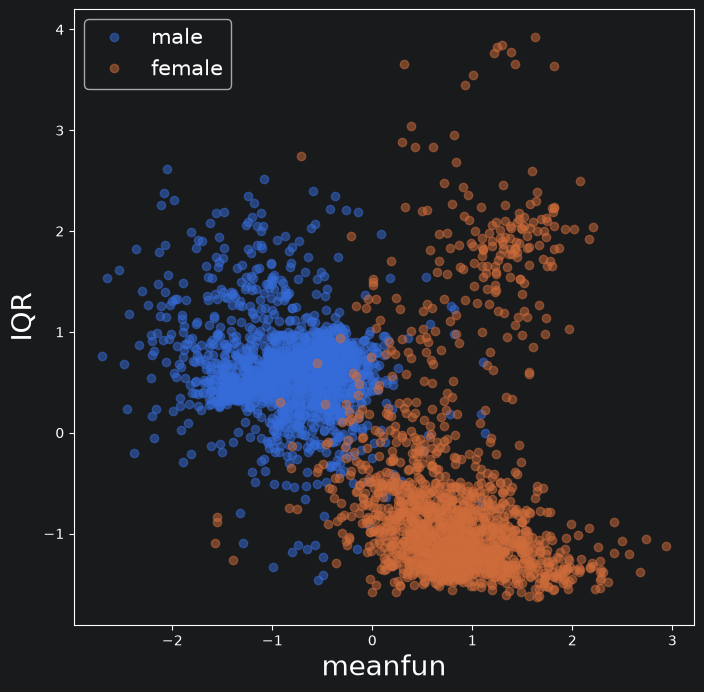

In [21]:
## Scatter of the top two features
c1, c2 = rank.index[:2]

f, ax = plt.subplots(figsize=(8, 8))
plt.plot(X[c1][I_m], X[c2][I_m], 'o', label="male", alpha=.5)
plt.plot(X[c1][I_f], X[c2][I_f], 'o', label="female", alpha=.5)
plt.xlabel(c1, fontsize=20)
plt.ylabel(c2, fontsize=20)
plt.legend(fontsize=15)

## Question 2
Fit Linear Regression, Logistic Regression and QDA, first on the two most indicative features
from Question 1, then on all 20 features, and compare.

In [22]:
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.model_selection import train_test_split

## Split once on all features, so the two-feature and all-feature models see the same rows
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=0)

feats2 = [c1, c2]   ## top two features from the Question 1 ranking
print("Two features used:", feats2)

Two features used: ['meanfun', 'IQR']


In [23]:
## Linear regression as a classifier: regress on the one-hot (dummy) labels and
## predict the class whose column gets the larger fitted value, as in the master file.
## Wrapping it in a class gives it the same predict/score interface as the sklearn classifiers.
class LinRegClassifier:
    def fit(self, X, y):
        Y = pd.get_dummies(y)
        self.classes_ = Y.columns.to_numpy()
        self.lr = LinearRegression().fit(X, Y.astype(float))
        return self

    def predict(self, X):
        return self.classes_[np.argmax(self.lr.predict(X), axis=1)]

    def predict_proba(self, X):
        ## not a true probability (can fall outside [0,1]), but it's the fitted "male" score
        return self.lr.predict(X)

    def score(self, X, y):
        return np.mean(self.predict(X) == np.asarray(y))

### Two-feature fits

In [24]:
models2 = {
    "Linear Regression": LinRegClassifier(),
    "Logistic Regression": LogisticRegression(),
    "QDA": QuadraticDiscriminantAnalysis(store_covariance=True),
}

for name, m in models2.items():
    m.fit(X_train[feats2], y_train)
    print("%-20s train: %.3f   test: %.3f" % (name, m.score(X_train[feats2], y_train),
                                             m.score(X_test[feats2], y_test)))

Linear Regression    train: 0.965   test: 0.956
Logistic Regression  train: 0.968   test: 0.960
QDA                  train: 0.969   test: 0.962


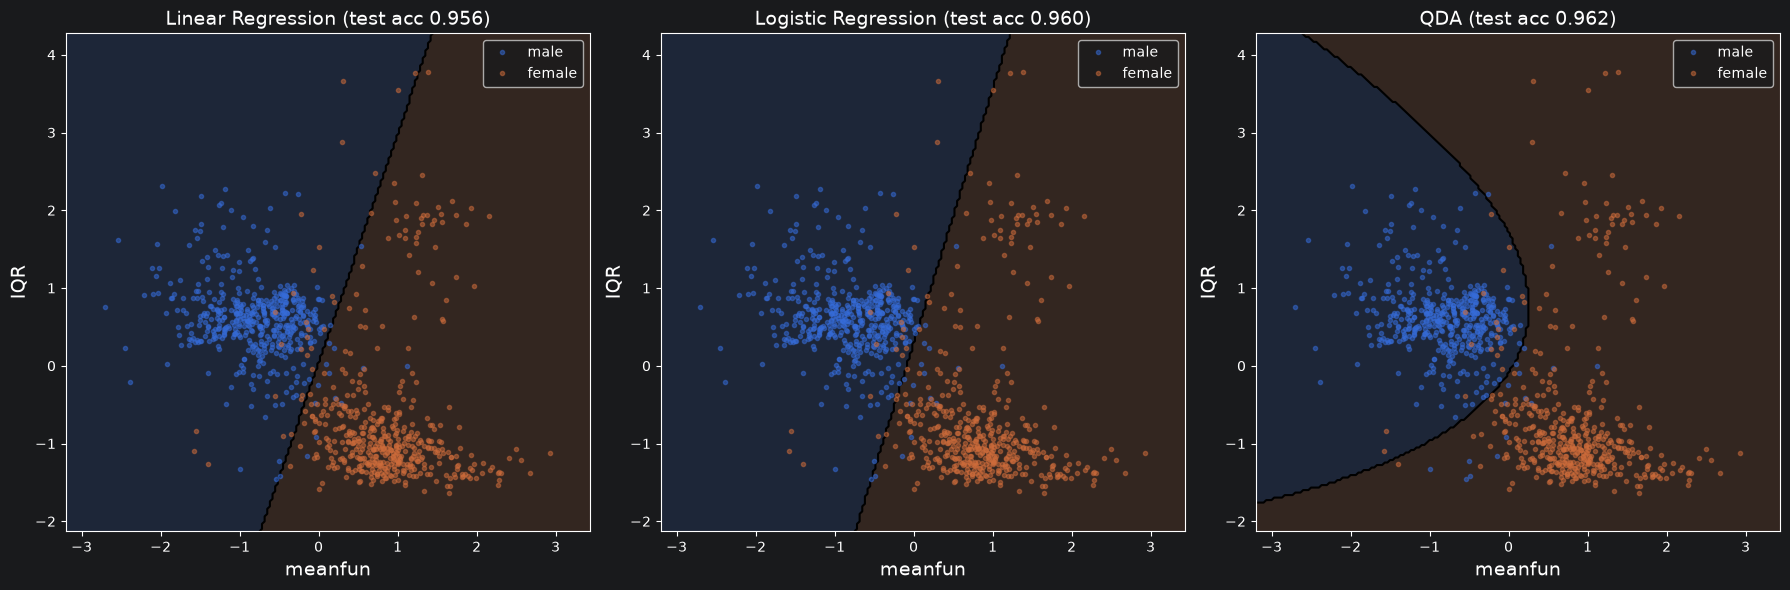

In [25]:
def plot_fit(Xd, yd, model, ax, title):
    col0, col1 = Xd.columns

    ## Shade the predicted region on a grid
    pad = .5
    xm, xM = Xd[col0].min() - pad, Xd[col0].max() + pad
    ym, yM = Xd[col1].min() - pad, Xd[col1].max() + pad
    XX, YY = np.meshgrid(np.linspace(xm, xM, 200), np.linspace(ym, yM, 200))
    grid = pd.DataFrame(np.c_[XX.ravel(), YY.ravel()], columns=[col0, col1])
    ZZ = (model.predict(grid) == "male").reshape(XX.shape)
    ax.contourf(XX, YY, ZZ, levels=[-.5, .5, 1.5], colors=["C1", "C0"], alpha=.15)
    ax.contour(XX, YY, ZZ, levels=[.5], colors="black", linewidths=1.5)

    ## Data points
    ax.plot(Xd[col0][yd == "male"], Xd[col1][yd == "male"], 'o', ms=3, alpha=.5, color="C0", label="male")
    ax.plot(Xd[col0][yd == "female"], Xd[col1][yd == "female"], 'o', ms=3, alpha=.5, color="C1", label="female")

    ax.set_xlim(xm, xM); ax.set_ylim(ym, yM)
    ax.set_xlabel(col0, fontsize=14); ax.set_ylabel(col1, fontsize=14)
    ax.set_title(title, fontsize=14)
    ax.legend()

f, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, (name, m) in zip(axes, models2.items()):
    plot_fit(X_test[feats2], y_test, m, ax, "%s (test acc %.3f)" % (name, m.score(X_test[feats2], y_test)))
plt.tight_layout()

### All-feature fits
Several features are exact linear combinations of others (`centroid` = `meanfreq`, `IQR` = `Q75` - `Q25`,
`dfrange` = `maxdom` - `mindom`), so the class covariance matrices are singular. A small `reg_param`
keeps QDA from breaking on that. We also raise `max_iter` so logistic regression converges.

In [26]:
models_all = {
    "Linear Regression": LinRegClassifier(),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "QDA": QuadraticDiscriminantAnalysis(reg_param=0.01),
}

for name, m in models_all.items():
    m.fit(X_train, y_train)

results = pd.DataFrame({
    "2 feat train": [m.score(X_train[feats2], y_train) for m in models2.values()],
    "2 feat test":  [m.score(X_test[feats2], y_test)   for m in models2.values()],
    "all train":    [m.score(X_train, y_train)          for m in models_all.values()],
    "all test":     [m.score(X_test, y_test)            for m in models_all.values()],
}, index=models2.keys())

results.round(3)

,2 feat train,2 feat test,all train,all test
Linear Regression,0.965,0.956,0.973,0.962
Logistic Regression,0.968,0.960,0.978,0.965
QDA,0.969,0.962,0.973,0.959


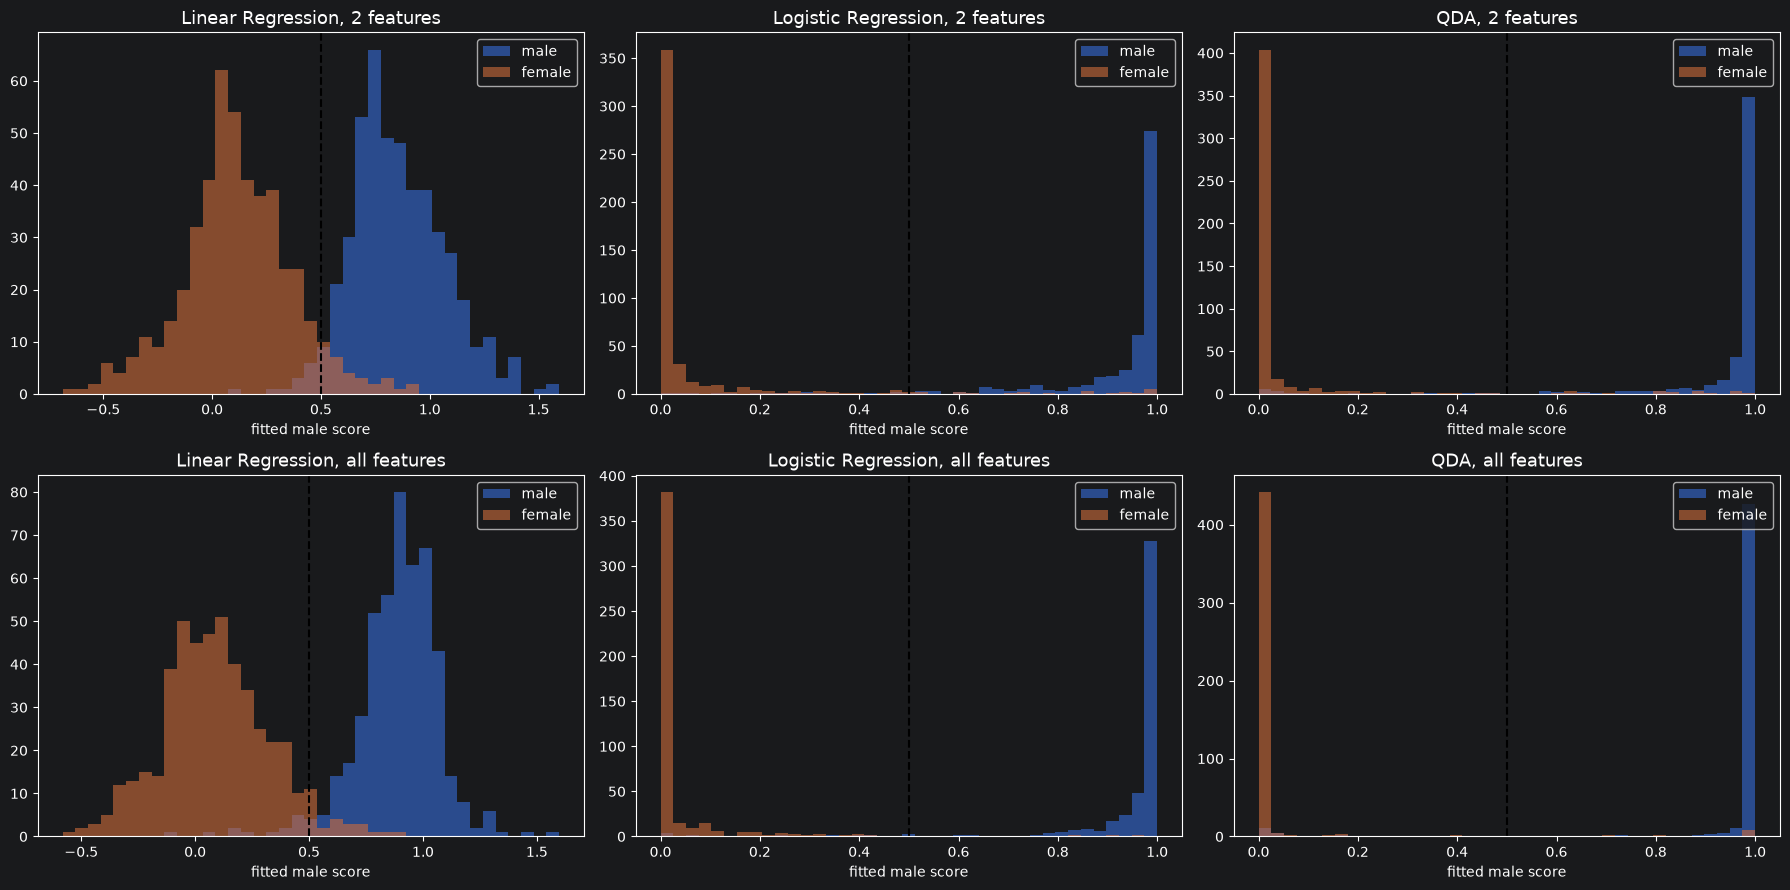

In [27]:
## A 20-dimensional boundary can't be drawn directly, so instead we graph each model's
## fitted "male" score on the test set, split by true label. Good separation means
## the two histograms barely overlap; the dashed line is the decision threshold.
f, axes = plt.subplots(2, 3, figsize=(18, 9))

for row, (models, feats, tag) in enumerate([(models2, feats2, "2 features"),
                                            (models_all, list(X.columns), "all features")]):
    for ax, (name, m) in zip(axes[row], models.items()):
        p = m.predict_proba(X_test[feats])
        p_male = p[:, list(m.classes_).index("male")]
        bins = np.linspace(min(p_male.min(), 0), max(p_male.max(), 1), 40)
        ax.hist(p_male[y_test == "male"], bins=bins, alpha=.6, color="C0", label="male")
        ax.hist(p_male[y_test == "female"], bins=bins, alpha=.6, color="C1", label="female")
        ax.axvline(.5, color="black", ls="--")
        ax.set_title("%s, %s" % (name, tag), fontsize=13)
        ax.set_xlabel("fitted male score")
        ax.legend()

plt.tight_layout()

In [29]:
from sklearn.metrics import confusion_matrix

for name in models2:
    print(name)
    print("  2 features:\n", confusion_matrix(y_test, models2[name].predict(X_test[feats2]), labels=["male", "female"]))
    print("  all features:\n", confusion_matrix(y_test, models_all[name].predict(X_test), labels=["male", "female"]))

Linear Regression
  2 features:
 [[462  13]
 [ 29 447]]
  all features:
 [[460  15]
 [ 21 455]]
Logistic Regression
  2 features:
 [[459  16]
 [ 22 454]]
  all features:
 [[458  17]
 [ 16 460]]
QDA
  2 features:
 [[458  17]
 [ 19 457]]
  all features:
 [[453  22]
 [ 17 459]]


### Discussion: two-feature vs. all-feature fits

**Accuracy (test set, 951 voices):**

| Model | 2 features (`meanfun`, `IQR`) | All 20 features | Change |
|---|---|---|---|
| Linear Regression | 0.956 | 0.962 | +0.6 pts |
| Logistic Regression | 0.960 | 0.965 | +0.5 pts |
| QDA | 0.962 | 0.959 | −0.3 pts |

**Two-feature fits.** `meanfun` alone gets 95% single-feature accuracy, and adding `IQR` raises all three models to about 96%.
The boundary plots show why: males form a tight cluster at low `meanfun` and positive `IQR`, while most females sit at high `meanfun` and
negative `IQR`. Linear and logistic regression draw almost the same straight line. It tilts upward, so a voice with a larger `IQR`
needs a higher `meanfun` to be labelled female. QDA instead draws a curve that wraps around the male cluster. Because the male cluster
is much tighter than the female one, QDA's unequal class covariances produce a boundary that bends around it. This makes QDA the best two-feature model, though only
slightly. A small second group of females at high `IQR` (around 2) falls on the female side for every model. Most errors come from the overlap
region near `meanfun` ≈ 0. Linear regression's errors are lopsided: it labels 29 females as male but only 13 males as female.

**All-feature fits.** Using all 20 features improves linear and logistic regression by only about half a percentage point, and QDA gets slightly
*worse*. The correlation heatmap explains this. Most of the extra features are near-copies of each other (`centroid` = `meanfreq`, the
frequency-quantile block) or carry little class information (`skew`, `kurt`, `modindx` are near chance on their own). They add
almost nothing beyond `meanfun`. QDA suffers most because it must estimate two full 20×20 covariance matrices. Its train/test gap grows
from 0.7 pts (2 features) to 1.4 pts (all features), a sign of overfitting. The score histograms show the same thing: all-feature QDA pushes nearly
every voice to a probability of exactly 0 or 1, including the ones it gets wrong, so it is overconfident. Logistic regression
benefits most from the extra features, cutting females mislabelled as male from 22 to 16.

**Graphs of the fits.** In every histogram the two classes separate cleanly, with a thin overlap near the threshold, which matches the ~96% accuracy.
Linear regression's scores are not probabilities: they run from about −0.6 to 1.6, and its overlap around 0.5 is wider than logistic regression's.

**Caveat.** With 951 test points, one standard error of accuracy is about 0.6 pts. So the differences between the three methods, and between
2 and 20 features, are all within noise for this single split.

**Conclusion.** Two well-chosen features (`meanfun`, `IQR`) give essentially all of the classification power, about 96%. They also give a model whose
decision boundary can be plotted and interpreted. Adding the other 18 features buys at most about half a point of accuracy, makes the model
uninterpretable, and in the case of QDA introduces overfitting.